# 34753 Robotics: Exam Toolkit (Python)

A ready-to-use notebook for the MCQ exam (15 Dec 2026). **Run the "Library" cells once** (Section 0), then go to the section of the question, **change the numbers in the `INPUT` cell** and run it.

Every example is pre-filled with a real exam question (Winter 2025-26 MCQ or the 2016–2020 exams), so you can see the expected answer next to the code.

| Section | Exam questions | Main functions |
|---|---|---|
| 1 Rotations & transforms | Q1.1, Q1.2 | `rotx/roty/rotz`, `trans`, `Hrot`, `compose`, `Hinv`, `frame_from_axes`, `frame_from_points`, `zyz_from_R`, `rpy_from_R`, `axis_angle_from_R` |
| 2 DH & forward kinematics | Q2.2 | `dh`, `Robot(...).fk`, `.print_frames`, `dh_from_A` |
| 3 Inverse kinematics | Q2.3 | `ik_2r`, `ik_articulated`, `wrist_center`, `Robot.ik_numeric` |
| 4 Velocity / Jacobian | Q3.1 | `Robot.jacobian`, `jac_2r`, `joint_rates`, `statics`, `skew` |
| 5 Trajectories | Q3.2 | `cubic`, `quintic`, `poly_from_conditions`, `lspb`, `jerk_profile` |
| 6 Vision | Q4.1–Q4.4 | `Camera`, `project`, `backproject`, `to_frame`, `stereo_depth` |
| 7 Control | Q5.1, Q5.2 | `tf_info`, `dc_motor`, `motor_position_loop`, `final_value`, `step_response`, `pd_design` |
| 8 Dynamics | (project) | `euler_lagrange`, inertia helpers |
| 9 Self-test | all | re-solves the whole 2025-26 MCQ |

**Conventions**
- Angles are in **degrees** by default (`deg=True`). Pass `deg=False` for radians.
- Joint *rates* (rad/s) and the Jacobian always use **radians**.
- Lengths: use one unit for a whole problem (mm *or* m).
- Symbolic work: pass `sympy` symbols instead of numbers (e.g. `q1 = sp.symbols('q1')`). Symbolic angles are treated as **radians**; plain numbers like `90` are still degrees.

**Before the exam:** open this file in VS Code, choose the kernel **Python 3.14 (global)** (it has numpy, sympy, matplotlib; the `.venvrobotics` venv does not have Jupyter). Run *Run All* once at home to be sure everything works offline.

---
# 0. Library (run these cells first)

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from math import factorial
np.set_printoptions(precision=4, suppress=True, linewidth=130)
sp.init_printing()

DEG = np.pi / 180
s, t = sp.symbols('s t')          # Laplace variable and time (symbolic)

def show(name, M, dec=4):
    """Pretty-print a numeric matrix/vector (or a sympy object)."""
    if isinstance(M, sp.Basic) or isinstance(M, sp.MatrixBase):
        print(f"{name} ="); display(M); return
    print(f"{name} =\n{np.round(np.asarray(M, dtype=float), dec)}\n")

def _is_sym(*xs):
    return any(isinstance(x, (sp.Basic, sp.MatrixBase)) for x in xs)

def _cs(angle, deg, sym):
    """cos, sin of an angle. Numbers are degrees if deg=True; sympy symbols are radians."""
    if sym:
        a = sp.sympify(angle)
        if deg and a.is_number:
            a = a * sp.pi / 180
        return sp.cos(a), sp.sin(a)
    a = np.deg2rad(angle) if deg else angle
    return np.cos(a), np.sin(a)

def _mat(rows, sym):
    return sp.simplify(sp.Matrix(rows)) if sym else np.array(rows, dtype=float)

def wrap180(a):
    """Wrap an angle in degrees to (-180, 180]."""
    a = (np.asarray(a, dtype=float) + 180.0) % 360.0 - 180.0
    return np.where(a == -180.0, 180.0, a)

print("core loaded")

core loaded


In [2]:
# ---------- 1. Rotations and homogeneous transforms ----------
def rotx(th, deg=True):
    sym = _is_sym(th); c, s_ = _cs(th, deg, sym)
    return _mat([[1, 0, 0], [0, c, -s_], [0, s_, c]], sym)

def roty(th, deg=True):
    sym = _is_sym(th); c, s_ = _cs(th, deg, sym)
    return _mat([[c, 0, s_], [0, 1, 0], [-s_, 0, c]], sym)

def rotz(th, deg=True):
    sym = _is_sym(th); c, s_ = _cs(th, deg, sym)
    return _mat([[c, -s_, 0], [s_, c, 0], [0, 0, 1]], sym)

def rot(axis, th, deg=True):
    return {'x': rotx, 'y': roty, 'z': rotz}[axis](th, deg)

def H(R=None, p=(0, 0, 0)):
    """Build a 4x4 homogeneous matrix from R (3x3) and p (3)."""
    sym = isinstance(R, sp.MatrixBase) or _is_sym(*p)
    if sym:
        R = sp.eye(3) if R is None else sp.Matrix(R)
        T = sp.eye(4); T[:3, :3] = R; T[:3, 3] = sp.Matrix(list(p)); return T
    T = np.eye(4)
    if R is not None: T[:3, :3] = R
    T[:3, 3] = p
    return T

def trans(x=0, y=0, z=0):
    return H(None, (x, y, z))

def Hrot(axis, th, deg=True):
    return H(rot(axis, th, deg))

def Hinv(T):
    """Inverse of a homogeneous transform: [R^T, -R^T o; 0 1]."""
    if isinstance(T, sp.MatrixBase):
        R = T[:3, :3]; o = T[:3, 3]
        Ti = sp.eye(4); Ti[:3, :3] = R.T; Ti[:3, 3] = -R.T * o; return sp.simplify(Ti)
    T = np.asarray(T, float); R = T[:3, :3]; o = T[:3, 3]
    return H(R.T, -R.T @ o)

def compose(steps, deg=True, verbose=True, start=None):
    """Build T from a sequence of moves.
    steps: list of (op, axis, value, frame)
        op    : 'rot' or 'trans'
        axis  : 'x', 'y' or 'z'
        frame : 'current' (post-multiply, T = T*M) or 'global'/'fixed'/'world' (pre-multiply, T = M*T)
    """
    sym = any(_is_sym(v) for _, _, v, _ in steps)
    T = (sp.eye(4) if sym else np.eye(4)) if start is None else start
    for op, axis, val, frame in steps:
        M = Hrot(axis, val, deg) if op == 'rot' else trans(**{axis: val})
        if sym and not isinstance(M, sp.MatrixBase): M = sp.Matrix(M)
        if frame == 'current':
            T = T @ M; where = 'right (current)'
        elif frame in ('global', 'fixed', 'world'):
            T = M @ T; where = 'left  (global)'
        else:
            raise ValueError("frame must be 'current' or 'global'")
        if verbose: print(f"{op:5s} {axis} {val!s:>8}  -> multiply on the {where}")
    if sym: T = sp.simplify(T)
    if verbose: show("T", T)
    return T

def check_rotation(R, tol=1e-3):
    """Check R^T R = I and det R = +1 (right-handed)."""
    R = np.asarray(R, float)
    ortho = np.allclose(R.T @ R, np.eye(3), atol=tol)
    det = np.linalg.det(R)
    print(f"R^T R = I : {ortho}   det R = {det:+.4f}  -> {'valid rotation' if ortho and abs(det-1)<tol else 'NOT a valid rotation'}")
    return ortho and abs(det - 1) < tol

def frame_from_axes(x1, y1, z1, origin):
    """H^0_1 from the axes of {1} written in {0} (Q1.2 style). Works with sympy entries."""
    cols = [x1, y1, z1]
    sym = _is_sym(*[c for v in cols for c in v], *origin)
    if sym:
        R = sp.Matrix([list(c) for c in cols]).T
        ok = sp.simplify(R[:, 0].cross(R[:, 1]) - R[:, 2]) == sp.zeros(3, 1)
    else:
        R = np.array(cols, float).T
        ok = np.allclose(np.cross(R[:, 0], R[:, 1]), R[:, 2])
    print("right-handed (x1 x y1 = z1):", ok)
    return H(R, origin)

def frame_from_points(P0, P1, P2):
    """Frame with origin P0, x towards P1, P2 in the xy-plane (exam 2020 P4)."""
    P0, P1, P2 = (np.asarray(P, float) for P in (P0, P1, P2))
    x = (P1 - P0) / np.linalg.norm(P1 - P0)
    z = np.cross(x, P2 - P0); z /= np.linalg.norm(z)
    y = np.cross(z, x)
    return H(np.column_stack([x, y, z]), P0)

# ---------- Euler / RPY / axis-angle ----------
def R_from_zyz(phi, theta, psi, deg=True):
    return rotz(phi, deg) @ roty(theta, deg) @ rotz(psi, deg)

def zyz_from_R(R):
    """ZYZ Euler angles (deg). Returns both solutions (theta>0 and theta<0)."""
    R = np.asarray(R, float)
    st = np.hypot(R[0, 2], R[1, 2])
    if st < 1e-9:
        print("SINGULAR (sin(theta)=0): only phi+psi (or phi-psi) is defined; phi set to 0")
        th = 0.0 if R[2, 2] > 0 else 180.0
        ps = np.degrees(np.arctan2(-R[0, 1], R[0, 0])) if R[2, 2] > 0 else np.degrees(np.arctan2(R[0, 1], -R[0, 0]))
        return [(0.0, th, ps)]
    sols = []
    for sg in (1, -1):
        th = np.arctan2(sg * st, R[2, 2])
        ph = np.arctan2(sg * R[1, 2], sg * R[0, 2])
        ps = np.arctan2(sg * R[2, 1], -sg * R[2, 0])
        sols.append(tuple(float(x) for x in np.round(np.degrees([ph, th, ps]), 4)))
    print("ZYZ (phi, theta, psi) in deg:", sols)
    return sols

def R_from_rpy(roll, pitch, yaw, deg=True):
    """R = Rz(yaw) Ry(pitch) Rx(roll)  (Spong: phi=yaw, theta=pitch, psi=roll)."""
    return rotz(yaw, deg) @ roty(pitch, deg) @ rotx(roll, deg)

def rpy_from_R(R):
    """Roll (about x), pitch (about y), yaw (about z) in deg, R = Rz(yaw)Ry(pitch)Rx(roll). Both solutions."""
    R = np.asarray(R, float)
    cp = np.hypot(R[0, 0], R[1, 0])
    if cp < 1e-9:
        print("SINGULAR (pitch = +-90): only roll+-yaw is defined")
    pitch = np.arctan2(-R[2, 0], cp)
    yaw = np.arctan2(R[1, 0], R[0, 0])
    roll = np.arctan2(R[2, 1], R[2, 2])
    s1 = np.degrees([roll, pitch, yaw])
    s2 = wrap180(np.array([s1[0] + 180, 180 - s1[1], s1[2] + 180]))
    out = [tuple(float(x) for x in np.round(s1, 4)), tuple(float(x) for x in np.round(s2, 4))]
    print("RPY (roll_x, pitch_y, yaw_z) in deg:", out)
    return out

def skew(w):
    """S(w) such that S(w) r = w x r."""
    if _is_sym(*w):
        wx, wy, wz = w; return sp.Matrix([[0, -wz, wy], [wz, 0, -wx], [-wy, wx, 0]])
    wx, wy, wz = np.asarray(w, float)
    return np.array([[0, -wz, wy], [wz, 0, -wx], [-wy, wx, 0]])

def unskew(S):
    return np.array([S[2, 1], S[0, 2], S[1, 0]], dtype=float)

def R_from_axis_angle(k, theta, deg=True):
    """Rodrigues: R = I + sin(th) S(k) + (1-cos(th)) S(k)^2 (k normalised)."""
    k = np.asarray(k, float); k = k / np.linalg.norm(k)
    th = np.deg2rad(theta) if deg else theta
    K = skew(k)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K

def axis_angle_from_R(R):
    R = np.asarray(R, float)
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    if abs(np.sin(th)) > 1e-9:
        k = np.array([R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]]) / (2 * np.sin(th))
    elif th < 1e-9:
        print("theta = 0: any axis"); k = np.array([0, 0, 1.0])
    else:  # theta = 180
        B = (R + np.eye(3)) / 2; i = np.argmax(np.diag(B)); k = B[:, i] / np.sqrt(B[i, i])
    print(f"axis k = {np.round(k, 4)}, angle = {np.degrees(th):.4f} deg")
    return k, np.degrees(th)

print("rotations / transforms loaded")

rotations / transforms loaded


In [3]:
# ---------- 2. Denavit-Hartenberg and the Robot class ----------
def dh(theta, d, a, alpha, deg=True):
    """A_i = Rot_z(theta) Trans_z(d) Trans_x(a) Rot_x(alpha)."""
    sym = _is_sym(theta, d, a, alpha)
    ct, st = _cs(theta, deg, sym); ca, sa = _cs(alpha, deg, sym)
    rows = [[ct, -st * ca, st * sa, a * ct],
            [st, ct * ca, -ct * sa, a * st],
            [0, sa, ca, d],
            [0, 0, 0, 1]]
    return _mat(rows, sym)

def dh_from_A(A):
    """Read (theta, d, a, alpha) in deg from a single DH matrix (exam 2016 P2)."""
    A = np.asarray(A, float)
    theta = np.arctan2(A[1, 0], A[0, 0]); alpha = np.arctan2(A[2, 1], A[2, 2])
    d = A[2, 3]; a = A[0, 3] * np.cos(theta) + A[1, 3] * np.sin(theta)
    out = dict(theta=np.degrees(theta), d=d, a=a, alpha=np.degrees(alpha))
    print({k: round(float(v), 4) for k, v in out.items()})
    ok = np.allclose(dh(out['theta'], d, a, out['alpha']), A, atol=1e-6)
    print("A is a valid DH matrix:", ok)
    return out

class Robot:
    """Serial robot from a DH table.
    table : list of rows (theta, d, a, alpha). These are the CONSTANT parts / offsets:
            for a revolute joint, theta_i = table_theta + q_i; for a prismatic joint, d_i = table_d + q_i.
            (If the exam gives the table 'in the configuration shown', use q = 0.)
    types : string like 'RRR', 'RRP', 'RRRRRR'
    deg   : table angles and revolute q given in degrees (True) or radians (False)
    """
    def __init__(self, table, types, deg=True, name="robot"):
        assert len(table) == len(types), "one type letter per DH row"
        self.table, self.types, self.deg, self.name = table, types.upper(), deg, name
        self.n = len(table)

    def _rows(self, q):
        q = [0] * self.n if q is None else list(q)
        rows = []
        for (th, d, a, al), qi, ty in zip(self.table, q, self.types):
            sym = _is_sym(th, d, a, al, qi)
            conv = (sp.pi / 180 if sym else DEG) if self.deg else 1
            th_r = sp.sympify(th) * conv if sym else th * conv
            al_r = sp.sympify(al) * conv if sym else al * conv
            if ty == 'R':
                qi_r = qi if (_is_sym(qi) and not sp.sympify(qi).is_number) else qi * conv
                th_r = th_r + qi_r
            else:
                d = d + qi
            rows.append((th_r, d, a, al_r))
        return rows

    def frames(self, q=None):
        """[T^0_0, T^0_1, ..., T^0_n]"""
        rows = self._rows(q)
        sym = any(_is_sym(*r) for r in rows)
        T = sp.eye(4) if sym else np.eye(4); Ts = [T]
        for r in rows:
            A = dh(*r, deg=False)
            T = sp.simplify(T * A) if sym else T @ A
            Ts.append(T)
        return Ts

    def A(self, i, q=None):
        """A_i (1-based) alone."""
        return dh(*self._rows(q)[i - 1], deg=False)

    def fk(self, q=None):
        return self.frames(q)[-1]

    def print_frames(self, q=None, dec=3):
        """Print origin and axes of every frame in base coordinates (great for checking a DH table)."""
        for i, T in enumerate(self.frames(q)):
            T = np.asarray(T, float)
            print(f"frame {i}: o={np.round(T[:3,3],dec)}  x={np.round(T[:3,0],dec)}  z={np.round(T[:3,2],dec)}")

    def jacobian(self, q=None):
        """Geometric Jacobian 6xn: [v; w] = J qdot, qdot in rad/s (revolute) or length/s (prismatic)."""
        Ts = self.frames(q)
        sym = isinstance(Ts[-1], sp.MatrixBase)
        on = Ts[-1][:3, 3]
        J = sp.zeros(6, self.n) if sym else np.zeros((6, self.n))
        for i in range(self.n):
            z = Ts[i][:3, 2]; o = Ts[i][:3, 3]
            if self.types[i] == 'R':
                if sym:
                    J[:3, i] = z.cross(on - o); J[3:, i] = z
                else:
                    J[:3, i] = np.cross(z, on - o); J[3:, i] = z
            else:
                J[:3, i] = z
        return sp.simplify(J) if sym else J

    def ik_numeric(self, p_target, q0=None, R_target=None, n_starts=30, iters=300, tol=1e-8, seed=0, verbose=True):
        """Numerical IK (damped least squares) from many random starts; returns the distinct solutions.
        p_target: 3-vector, R_target: optional 3x3 orientation. Revolute angles returned in deg if self.deg."""
        rng = np.random.default_rng(seed)
        conv = DEG if self.deg else 1.0
        p_target = np.asarray(p_target, float)
        sols = []
        starts = ([np.asarray(q0, float)] if q0 is not None else []) + \
                 [np.array([rng.uniform(-180, 180) if ty == 'R' else rng.uniform(0, 1) * np.linalg.norm(p_target)
                            for ty in self.types]) for _ in range(n_starts)]
        for qs in starts:
            q = qs.astype(float).copy()
            if not self.deg:  # random starts were generated in degrees
                q = np.array([qi * DEG if ty == 'R' else qi for qi, ty in zip(q, self.types)])
            for _ in range(iters):
                T = self.fk(q); e = p_target - T[:3, 3]
                J = self.jacobian(q)
                if R_target is not None:
                    Rc = T[:3, :3]; Rt = np.asarray(R_target, float)
                    eo = 0.5 * sum(np.cross(Rc[:, k], Rt[:, k]) for k in range(3))
                    e = np.r_[e, eo]
                else:
                    J = J[:3]
                if np.linalg.norm(e) < tol: break
                lam = 1e-3 * max(1.0, np.linalg.norm(p_target))
                dq = J.T @ np.linalg.solve(J @ J.T + lam**2 * np.eye(J.shape[0]), e)
                dq = np.array([dqi / conv if ty == 'R' else dqi for dqi, ty in zip(dq, self.types)])
                q = q + dq
            if np.linalg.norm(e) < 1e-6:
                qn = np.array([wrap180(qi) if (ty == 'R' and self.deg) else
                               (np.arctan2(np.sin(qi), np.cos(qi)) if ty == 'R' else qi)
                               for qi, ty in zip(q, self.types)], dtype=float)
                if not any(np.allclose(qn, s_, atol=1e-3) for s_ in sols):
                    sols.append(qn)
        if verbose:
            unit = 'deg' if self.deg else 'rad'
            print(f"{len(sols)} distinct solution(s) (revolute in {unit}):")
            for s_ in sols: print("  q =", np.round(s_, 4))
        return sols

print("DH / Robot loaded")

DH / Robot loaded


In [4]:
# ---------- 3. Analytic inverse kinematics ----------
def fk_2r(t1, t2, a1, a2, deg=True):
    c = np.deg2rad if deg else (lambda x: x)
    t1, t2 = c(t1), c(t2)
    return np.array([a1*np.cos(t1) + a2*np.cos(t1+t2), a1*np.sin(t1) + a2*np.sin(t1+t2)])

def ik_2r(x, y, a1, a2, deg=True, verbose=True):
    """Planar 2R: both solutions. cos(t2) = (x^2+y^2-a1^2-a2^2)/(2 a1 a2)."""
    D = (x**2 + y**2 - a1**2 - a2**2) / (2 * a1 * a2)
    if abs(D) > 1 + 1e-12:
        print(f"UNREACHABLE: cos(theta2) = {D:.4f}"); return []
    D = np.clip(D, -1, 1); sols = []
    for sg in (+1, -1):
        t2 = np.arctan2(sg * np.sqrt(1 - D**2), D)
        t1 = np.arctan2(y, x) - np.arctan2(a2 * np.sin(t2), a1 + a2 * np.cos(t2))
        sol = (wrap180(np.degrees(t1)), np.degrees(t2)) if deg else (np.arctan2(np.sin(t1), np.cos(t1)), t2)
        sols.append(tuple(float(v) for v in sol))
    if verbose:
        print(f"cos(theta2) = {D:.4f}")
        for (t1_, t2_), name in zip(sols, ["theta2 > 0", "theta2 < 0"]):
            print(f"  {name}: theta1 = {t1_:9.4f}, theta2 = {t2_:9.4f}   FK check -> {np.round(fk_2r(t1_, t2_, a1, a2, deg), 4)}")
        print("  -> pick the one that matches the figure (elbow up / down).")
    return sols

def wrist_center(T06, d6):
    """o_c = o_6 - d6 * z_6"""
    T06 = np.asarray(T06, float)
    return T06[:3, 3] - d6 * T06[:3, 2]

def ik_articulated(xc, yc, zc, d1, a2, a3, deg=True, verbose=True):
    """Elbow manipulator (RRR, DH: (q1,d1,0,90),(q2,0,a2,0),(q3,0,a3,0)). Up to 4 solutions for the wrist centre."""
    r2 = xc**2 + yc**2; s_ = zc - d1
    D = (r2 + s_**2 - a2**2 - a3**2) / (2 * a2 * a3)
    if abs(D) > 1 + 1e-12:
        print(f"UNREACHABLE: cos(theta3) = {D:.4f}"); return []
    D = np.clip(D, -1, 1); sols = []
    for t1, rsign in ((np.arctan2(yc, xc), 1), (np.arctan2(yc, xc) + np.pi, -1)):
        for sg in (1, -1):
            t3 = np.arctan2(sg * np.sqrt(1 - D**2), D)
            t2 = np.arctan2(s_, rsign * np.sqrt(r2)) - np.arctan2(a3 * np.sin(t3), a2 + a3 * np.cos(t3))
            q = np.array([t1, t2, t3])
            sols.append(wrap180(np.degrees(q)) if deg else np.arctan2(np.sin(q), np.cos(q)))
    if verbose:
        rob = Robot([(0, d1, 0, 90), (0, 0, a2, 0), (0, 0, a3, 0)], 'RRR', deg=deg)
        for q in sols:
            print("q =", np.round(q, 4), "  FK check ->", np.round(rob.fk(q)[:3, 3], 4))
    return sols

def ik_spherical_wrist(R03, R06):
    """theta4, theta5, theta6 for a standard spherical wrist = ZYZ angles of R36 = R03^T R06."""
    R36 = np.asarray(R03, float).T @ np.asarray(R06, float)
    show("R36", R36)
    return zyz_from_R(R36)

print("IK loaded")

IK loaded


In [5]:
# ---------- 4. Velocity kinematics ----------
def jac_2r(t1, t2, a1, a2, deg=True):
    """Linear-velocity Jacobian of a planar 2R arm (2x2)."""
    c = np.deg2rad if deg else (lambda x: x)
    t1, t2 = c(t1), c(t2)
    return np.array([[-a1*np.sin(t1) - a2*np.sin(t1+t2), -a2*np.sin(t1+t2)],
                     [ a1*np.cos(t1) + a2*np.cos(t1+t2),  a2*np.cos(t1+t2)]])

def joint_rates(J, xi, b=None, verbose=True):
    """Solve J qdot = xi. Square -> inverse; wide (redundant) -> J^+ xi (+ null-space b); tall -> least squares."""
    J = np.asarray(J, float); xi = np.asarray(xi, float)
    m, n = J.shape
    if m == n:
        d = np.linalg.det(J)
        if verbose: print(f"det J = {d:.6g}" + ("   <-- SINGULAR" if abs(d) < 1e-9 else ""))
        qd = np.linalg.solve(J, xi)
    elif m < n:
        Jp = J.T @ np.linalg.inv(J @ J.T); qd = Jp @ xi
        if b is not None: qd = qd + (np.eye(n) - Jp @ J) @ np.asarray(b, float)
        if verbose: print("redundant: qdot = J^T (J J^T)^-1 xi" + (" + (I - J^+ J) b" if b is not None else ""))
    else:
        qd = np.linalg.solve(J.T @ J, J.T @ xi)
        if verbose: print("over-determined: least squares (J^T J)^-1 J^T xi")
    if verbose: print("qdot =", np.round(qd, 4), "  check J qdot =", np.round(J @ qd, 4))
    return qd

def statics(J, F):
    """Joint torques balancing an end-effector wrench F: tau = J^T F."""
    tau = np.asarray(J, float).T @ np.asarray(F, float)
    print("tau = J^T F =", np.round(tau, 4)); return tau

def singularities_sym(J, q_syms):
    """Symbolic det(J) (square J) or det(J J^T), and where it vanishes."""
    J = sp.Matrix(J)
    d = sp.simplify(J.det() if J.shape[0] == J.shape[1] else (J * J.T).det())
    print("det ="); display(sp.factor(d))
    try: print("zeros:", sp.solve(d, q_syms, dict=True))
    except Exception as e: print("solve failed:", e)
    return d

def velocity_to_frame(R, v):
    """Free vectors (velocity, force, axis) change frame with R only: v^0 = R^0_1 v^1."""
    return np.asarray(R, float) @ np.asarray(v, float)

print("velocity loaded")

velocity loaded


In [6]:
# ---------- 5. Trajectory planning ----------
def poly_from_conditions(conds, verbose=True):
    """Polynomial q(t) = c0 + c1 t + ... through arbitrary conditions.
    conds: list of (t, k, value) meaning d^k q / dt^k (t) = value. Degree = len(conds) - 1."""
    n = len(conds); M = np.zeros((n, n)); b = np.zeros(n)
    for r, (tt, k, val) in enumerate(conds):
        for j in range(k, n):
            M[r, j] = factorial(j) / factorial(j - k) * tt ** (j - k)
        b[r] = val
    c = np.linalg.solve(M, b)
    if verbose:
        for j, cj in enumerate(c): print(f"c{j} = {cj: .4f}")
    return c

def cubic(q0, qf, t0, tf, v0=0, vf=0, verbose=True):
    return poly_from_conditions([(t0, 0, q0), (t0, 1, v0), (tf, 0, qf), (tf, 1, vf)], verbose)

def quintic(q0, qf, t0, tf, v0=0, vf=0, a0=0, af=0, verbose=True):
    return poly_from_conditions([(t0, 0, q0), (t0, 1, v0), (t0, 2, a0),
                                 (tf, 0, qf), (tf, 1, vf), (tf, 2, af)], verbose)

def poly_eval(c, tt, k=0):
    """k-th derivative of the polynomial with coefficients c (c0 first) at time(s) tt."""
    p = np.polynomial.polynomial.Polynomial(c)
    return p.deriv(k)(tt) if k else p(tt)

def plot_poly(c, t0, tf, title="trajectory"):
    tt = np.linspace(t0, tf, 400)
    fig, ax = plt.subplots(1, 4, figsize=(15, 2.8))
    for k, name in enumerate(["q", "q dot", "q ddot", "jerk"]):
        ax[k].plot(tt, poly_eval(c, tt, k)); ax[k].set_title(name); ax[k].grid(True)
    fig.suptitle(title); plt.tight_layout(); plt.show()

def lspb(q0, qf, tf, V, verbose=True):
    """Linear segment with parabolic blends (trapezoidal velocity), t0 = 0. Returns q(t) function."""
    D = qf - q0
    if not (abs(D) / tf < abs(V) <= 2 * abs(D) / tf):
        print(f"V must satisfy {abs(D)/tf:.4g} < |V| <= {2*abs(D)/tf:.4g}"); return None
    V = np.sign(D) * abs(V); tb = (q0 - qf + V * tf) / V; acc = V / tb
    if verbose: print(f"blend time tb = {tb:.4f}, acceleration = {acc:.4f}, cruise speed = {V:.4f}")
    def q(tt):
        tt = np.asarray(tt, float)
        return np.where(tt <= tb, q0 + acc / 2 * tt**2,
               np.where(tt <= tf - tb, (qf + q0 - V * tf) / 2 + V * tt,
                        qf - acc / 2 * (tf - tt)**2))
    return q

def jerk_profile(segments, q0=0, v0=0, a0=0):
    """Integrate a piecewise-constant jerk profile exactly (works with sympy symbols).
    segments: list of (duration, jerk). Returns list of (q, v, a) at the end of each segment."""
    q, v, a = q0, v0, a0; out = []
    for T, j in segments:
        q = q + v * T + a * T**2 / 2 + j * T**3 / 6
        v = v + a * T + j * T**2 / 2
        a = a + j * T
        out.append((sp.simplify(q) if _is_sym(q) else q, sp.simplify(v) if _is_sym(v) else v, a))
    return out

print("trajectories loaded")

trajectories loaded


In [7]:
# ---------- 6. Vision ----------
class Camera:
    """Pinhole camera, exam convention:  u = lam*x/z, v = lam*y/z  [mm on the sensor]
       r = o_r + sign*alpha_x*u,  c = o_c + sign*alpha_y*v   (sign = -1 in the 34753 slides / MCQ)
    lam [mm], alpha_x, alpha_y [pix/mm] (= 1/s_x, 1/s_y).  If you are given focal lengths in pixels,
    use Camera.from_pixels(fx, fy, o_r, o_c)."""
    def __init__(self, lam, alpha_x, alpha_y, o_r, o_c, sign=-1):
        self.lam, self.ax, self.ay, self.o_r, self.o_c, self.sign = lam, alpha_x, alpha_y, o_r, o_c, sign
    @classmethod
    def from_pixels(cls, fx, fy, o_r, o_c, sign=-1):
        return cls(1.0, fx, fy, o_r, o_c, sign)
    def K(self):
        return np.array([[self.sign*self.ax*self.lam, 0, self.o_r],
                         [0, self.sign*self.ay*self.lam, self.o_c], [0, 0, 1]])

def project(P_cam, cam, verbose=True, labels=None, round_pix=True):
    """Points in the CAMERA frame (N x 3, same length unit as lam!) -> (u,v) on sensor and (r,c) pixels."""
    P = np.atleast_2d(np.asarray(P_cam, float))
    u = cam.lam * P[:, 0] / P[:, 2]; v = cam.lam * P[:, 1] / P[:, 2]
    r = cam.o_r + cam.sign * cam.ax * u; c = cam.o_c + cam.sign * cam.ay * v
    if verbose:
        for i in range(len(P)):
            name = labels[i] if labels else f"P{i+1}"
            print(f"{name}: (u,v) = ({u[i]: .4f}, {v[i]: .4f})   (r,c) = ({r[i]:.2f}, {c[i]:.2f})"
                  + (f"  -> [{round(r[i])}; {round(c[i])}]" if round_pix else ""))
    return np.c_[u, v], np.c_[r, c]

def backproject(r, c, z, cam):
    """Pixel (r,c) + known depth z -> point in the camera frame."""
    u = (r - cam.o_r) / (cam.sign * cam.ax); v = (c - cam.o_c) / (cam.sign * cam.ay)
    p = np.array([u * z / cam.lam, v * z / cam.lam, z])
    print("p_cam =", np.round(p, 4)); return p

def to_frame(T_a_b, P_b):
    """Points expressed in frame b (N x 3) -> frame a, using T^a_b."""
    P = np.atleast_2d(np.asarray(P_b, float))
    Ph = np.c_[P, np.ones(len(P))]
    return (np.asarray(T_a_b, float) @ Ph.T).T[:, :3]

def stereo_depth(lam, B, u1, u2):
    """Parallel stereo: z = lam * B / (u1 - u2) (u in the same unit as lam)."""
    z = lam * B / (u1 - u2); print(f"z = {z:.4f}"); return z

def depth_from_size(lam, size_world, size_sensor):
    """Object of known size parallel to the sensor: z = lam * size_world / size_sensor."""
    z = lam * size_world / size_sensor; print(f"z = {z:.4f}"); return z

print("vision loaded")

vision loaded


In [8]:
# ---------- 7. Control ----------
def tf_info(G, name="G"):
    """Poles, zeros, order and DC gain of a transfer function in s (sympy)."""
    G = sp.together(sp.simplify(G))
    num, den = sp.fraction(G)
    print(f"{name}(s) ="); display(sp.simplify(G))
    try:
        den_c = [complex(c) for c in sp.Poly(sp.expand(den), s).all_coeffs()]
        num_c = [complex(c) for c in sp.Poly(sp.expand(num), s).all_coeffs()]
        poles = np.roots(den_c); zeros = np.roots(num_c) if len(num_c) > 1 else np.array([])
        print(f"order (number of poles) = {len(poles)}")
        print("poles =", np.round(poles, 4)); print("zeros =", np.round(zeros, 4))
        print("stable (all Re<0):", bool(np.all(poles.real < 0)), "| marginal pole at 0:", bool(np.any(np.abs(poles) < 1e-9)))
    except Exception:
        print("symbolic coefficients -> denominator:"); display(sp.factor(den)); poles = None
    dc = sp.limit(G, s, 0); print("DC gain G(0) =", dc)
    return poles

def feedback(G, Hs=1):
    """Closed loop G / (1 + G H)."""
    return sp.simplify(G / (1 + G * Hs))

def final_value(F):
    """f(inf) = lim_{s->0} s F(s)  (valid only if s F(s) is stable)."""
    v = sp.limit(s * F, s, 0); print("final value =", v, f"≈ {complex(v).real:.6g}" if v.is_number and v.is_finite else ""); return v

def initial_value(F):
    v = sp.limit(s * F, s, sp.oo); print("initial value =", v); return v

def reflected(Jm, Jl, n, Bm=0, Bl=0):
    """Motor-side equivalents with gear ratio n = theta_m/theta_l: J = Jm + Jl/n^2, B = Bm + Bl/n^2."""
    J = Jm + Jl / n**2; B = Bm + Bl / n**2
    print(f"J_eq = {J}, B_eq = {B}"); return J, B

def dc_motor(L, R, Kb, Kt, J, B, output="angle"):
    """Armature-controlled DC motor V -> omega or V -> theta.
       (L s + R) I = V - Kb s Theta ;  (J s^2 + B s) Theta = Kt I"""
    w = Kt / ((L * s + R) * (J * s + B) + Kt * Kb)
    return sp.simplify(w / s if output == "angle" else w)

def motor_position_loop(C, L, R, Kb, Kt, J, B, n=1, ref=1, tau_l=0, verbose=True):
    """Position loop around a DC motor (motor side, J and B already reflected):
         V = C(s) (Theta_ref - Theta),  (L s + R) I = V - Kb s Theta,  (J s^2 + B s) Theta = Kt I - tau_l/n
       ref, tau_l are STEP amplitudes. Returns closed-loop Theta(s) and the steady-state error."""
    Th, I, V = sp.symbols('Theta I V')
    Tr = ref / s; Td = tau_l / s
    sol = sp.solve([sp.Eq(V, C * (Tr - Th)),
                    sp.Eq((L * s + R) * I, V - Kb * s * Th),
                    sp.Eq((J * s**2 + B * s) * Th, Kt * I - Td / n)], [Th, I, V], dict=True)[0]
    Theta = sp.simplify(sol[Th])
    ess = sp.limit(s * (Tr - Theta), s, 0)
    if verbose:
        den = sp.fraction(sp.together(sp.simplify(Theta)))[1]
        r_ = np.roots([complex(c) for c in sp.Poly(sp.expand(den), s).all_coeffs()])
        i0 = np.argmin(np.abs(r_)); r_ = np.delete(r_, i0)          # remove the s from the step input
        print("closed-loop poles:", np.round(r_, 4), "| stable:", bool(np.all(r_.real < 0)))
        print("steady-state error e_ss =", sp.nsimplify(ess) if ess.is_number else ess,
              f"≈ {float(ess):.6g}" if ess.is_number else "")
    return Theta, ess

def _expm(M):
    """Matrix exponential (scaling and squaring + Taylor), so we don't need scipy."""
    nrm = np.linalg.norm(M, 1); k = max(0, int(np.ceil(np.log2(nrm / 0.5))) if nrm > 0.5 else 0)
    A = M / 2**k; E = np.eye(len(M)); term = np.eye(len(M))
    for i in range(1, 25):
        term = term @ A / i; E = E + term
    for _ in range(k): E = E @ E
    return E

def step_response(G, t_end=10, amplitude=1, n=3000, plot=True, title="step response"):
    """Numeric step response of a NUMERIC sympy transfer function G(s) (strictly proper or proper)."""
    num, den = sp.fraction(sp.together(sp.simplify(G)))
    nc = np.array([float(c) for c in sp.Poly(sp.expand(num), s).all_coeffs()])
    dc = np.array([float(c) for c in sp.Poly(sp.expand(den), s).all_coeffs()])
    nc, dc = nc / dc[0], dc / dc[0]; N = len(dc) - 1
    nc = np.r_[np.zeros(N + 1 - len(nc)), nc]; Dff = nc[0]; nc = nc - Dff * dc   # strictly proper part
    A = np.zeros((N, N)); A[:-1, 1:] = np.eye(N - 1); A[-1, :] = -dc[1:][::-1]
    Bv = np.zeros(N); Bv[-1] = 1; Cv = nc[1:][::-1]
    dt = t_end / n; Maug = np.zeros((N + 1, N + 1)); Maug[:N, :N] = A; Maug[:N, N] = Bv
    E = _expm(Maug * dt); Ad, Bd = E[:N, :N], E[:N, N]
    x = np.zeros(N); y = np.zeros(n + 1); tt = np.linspace(0, t_end, n + 1)
    for k in range(n + 1):
        y[k] = Cv @ x + Dff * amplitude; x = Ad @ x + Bd * amplitude
    yf = y[-1]; info = {"final (at t_end)": yf}
    if abs(yf) > 1e-12:
        info["overshoot %"] = max(0.0, (y.max() - yf) / abs(yf) * 100)
        out = np.where(np.abs(y - yf) > 0.02 * abs(yf))[0]
        info["settling time 2%"] = tt[out[-1] + 1] if len(out) and out[-1] + 1 <= n else 0.0
        try:
            info["rise time 10-90%"] = tt[np.argmax(y >= 0.9 * yf)] - tt[np.argmax(y >= 0.1 * yf)]
        except Exception: pass
    print({k: round(float(v), 4) for k, v in info.items()})
    if plot:
        plt.figure(figsize=(7, 3)); plt.plot(tt, y); plt.grid(True); plt.xlabel("t [s]"); plt.title(title); plt.show()
    return tt, y, info

def second_order_specs(zeta, wn):
    """Standard 2nd-order step specs."""
    out = {"poles": np.roots([1, 2 * zeta * wn, wn**2])}
    if zeta < 1:
        out["%OS"] = 100 * np.exp(-np.pi * zeta / np.sqrt(1 - zeta**2))
        out["t_peak"] = np.pi / (wn * np.sqrt(1 - zeta**2))
    out["t_settle(2%)≈"] = 4 / (zeta * wn)
    for k, v in out.items(): print(f"{k}: {np.round(v, 4)}")
    return out

def zeta_from_OS(OS_percent):
    l = np.log(OS_percent / 100); z = -l / np.sqrt(np.pi**2 + l**2); print(f"zeta = {z:.4f}"); return z

def pd_design(J, B, wn, zeta=1.0):
    """Independent joint PD: closed loop J s^2 + (B+Kd) s + Kp  ->  Kp = J wn^2, Kd = 2 zeta wn J - B."""
    Kp = J * wn**2; Kd = 2 * zeta * wn * J - B
    print(f"Kp = {Kp:.4f}, Kd = {Kd:.4f}"); return Kp, Kd

print("control loaded")

control loaded


In [9]:
# ---------- 8. Dynamics (Euler-Lagrange) ----------
def euler_lagrange(q, qd, K, P, verbose=True):
    """q, qd: lists of sympy symbols; K = kinetic energy, P = potential energy (sympy expressions).
    Returns D(q), C(q,qd), g(q) with  D qdd + C qd + g = tau  (Christoffel symbols)."""
    n = len(q)
    D = sp.simplify(sp.hessian(K, qd))
    C = sp.zeros(n, n)
    for k in range(n):
        for j in range(n):
            C[k, j] = sp.simplify(sum(sp.Rational(1, 2) * (sp.diff(D[k, j], q[i]) + sp.diff(D[k, i], q[j])
                                                           - sp.diff(D[i, j], q[k])) * qd[i] for i in range(n)))
    g = sp.simplify(sp.Matrix([sp.diff(P, qi) for qi in q]))
    if verbose:
        print("D(q) ="); display(D); print("C(q,qd) ="); display(C); print("g(q) ="); display(g)
    return D, C, g

def kinetic_point_mass(m, p, q, qd):
    """1/2 m |v|^2 for a point (centre of mass) with position p(q) (sympy 3-vector)."""
    v = sp.Matrix(p).jacobian(q) * sp.Matrix(qd)
    return sp.Rational(1, 2) * m * (v.T * v)[0]

def I_box(m, a, b, c):
    """Box a x b x c about its centre: Ixx, Iyy, Izz."""
    return m * (b**2 + c**2) / 12, m * (a**2 + c**2) / 12, m * (a**2 + b**2) / 12

def I_rod(m, l, about="centre"):
    return m * l**2 / 12 if about == "centre" else m * l**2 / 3

print("dynamics loaded  ->  library ready ✔")

dynamics loaded  ->  library ready ✔


---
# 1. Rotations and homogeneous transforms (Q1.1, Q1.2)
**Rule:** move about the **current** frame → multiply on the **right**; about the **global/fixed** frame → multiply on the **left**.
### 1a. Sequence of moves → T (Q1.1)

In [10]:
# INPUT: (op, axis, value, frame)   op: 'rot' [deg] or 'trans' [length];  frame: 'current' or 'global'
steps = [
    ('rot',   'x', 60, 'current'),
    ('trans', 'y', 50, 'current'),
    ('rot',   'z', 40, 'global'),
    ('trans', 'x', 30, 'global'),
]
T = compose(steps)
check_rotation(T[:3, :3])
for k in range(4): print(f"column {k+1}: {np.round(T[:3, k], 3)}")
# expected Q1.1: (0.766,0.643,0) (-0.321,0.383,0.866) (0.557,-0.663,0.5) (13.93,19.15,43.3)

rot   x       60  -> multiply on the right (current)
trans y       50  -> multiply on the right (current)
rot   z       40  -> multiply on the left  (global)
trans x       30  -> multiply on the left  (global)
T =
[[ 0.766  -0.3214  0.5567 13.9303]
 [ 0.6428  0.383  -0.6634 19.1511]
 [ 0.      0.866   0.5    43.3013]
 [ 0.      0.      0.      1.    ]]

R^T R = I : True   det R = +1.0000  -> valid rotation
column 1: [0.766 0.643 0.   ]
column 2: [-0.321  0.383  0.866]
column 3: [ 0.557 -0.663  0.5  ]
column 4: [13.93  19.151 43.301]


### 1b. Frame described in words, with symbols (Q1.2)
Write each axis of {1} in {0} coordinates, and the origin of {1} in {0}.

In [11]:
L, Hh, W, l, h, w, a = sp.symbols('L H W ell h w a', positive=True)
# INPUT: x1 points along +y0, y1 along +x0, z1 along -z0; origin at (L-ell, a, H-h) in {0}
H01 = frame_from_axes(x1=(0, 1, 0), y1=(1, 0, 0), z1=(0, 0, -1), origin=(L - l, a, Hh - h))
H01

right-handed (x1 x y1 = z1): True


⎡0  1  0   L - ell⎤
⎢                 ⎥
⎢1  0  0      a   ⎥
⎢                 ⎥
⎢0  0  -1   H - h ⎥
⎢                 ⎥
⎣0  0  0      1   ⎦

### 1c. Inverse, point vs vector, chaining

In [12]:
# INPUT
T01 = H(rotz(90), (1, 2, 0))
p1  = np.array([1, 0, 0])       # a POINT in frame 1
v1  = np.array([1, 0, 0])       # a VECTOR (velocity/force) in frame 1

show("T01", T01); show("T10 = inv", Hinv(T01))
print("point  p0 = R p1 + o :", to_frame(T01, p1)[0])
print("vector v0 = R v1     :", T01[:3, :3] @ v1)

T01 =
[[ 0. -1.  0.  1.]
 [ 1.  0.  0.  2.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

T10 = inv =
[[ 0.  1.  0. -2.]
 [-1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]

point  p0 = R p1 + o : [1. 3. 0.]
vector v0 = R v1     : [0. 1. 0.]


### 1d. Euler ZYZ / RPY / axis–angle

In [13]:
# INPUT: any rotation matrix
R = R_from_zyz(30, 45, 60)
show("R", R)
zyz_from_R(R)               # -> (30, 45, 60) and the second solution
rpy_from_R(T[:3, :3])       # the Q1.1 rotation -> roll 60, pitch 0, yaw 40
axis_angle_from_R(rotz(90));

R =
[[-0.1268 -0.7803  0.6124]
 [ 0.9268  0.1268  0.3536]
 [-0.3536  0.6124  0.7071]]

ZYZ (phi, theta, psi) in deg: [(30.0, 45.0, 60.0), (-150.0, -45.0, -120.0)]
RPY (roll_x, pitch_y, yaw_z) in deg: [(60.0, -0.0, 40.0), (-120.0, 180.0, -140.0)]
axis k = [0. 0. 1.], angle = 90.0000 deg


### 1e. Frame from three points (exam 2020 P4)

In [14]:
# INPUT: origin P0, point on x-axis P1, point in xy-plane P2
show("T_task", frame_from_points([0.25, 0.25, 0.15], [0.4526, 0.3357, 0.15], [0.0942, 0.6184, 0.15]))

T_task =
[[ 0.921  -0.3896  0.      0.25  ]
 [ 0.3896  0.921  -0.      0.25  ]
 [ 0.      0.      1.      0.15  ]
 [ 0.      0.      0.      1.    ]]



---
# 2. DH parameters and forward kinematics (Q2.2)
$A_i=\text{Rot}_z(\theta_i)\,\text{Trans}_z(d_i)\,\text{Trans}_x(a_i)\,\text{Rot}_x(\alpha_i)$. Rows are `(theta, d, a, alpha)`.

`print_frames` prints every origin and the $x$, $z$ axes in base coordinates, so you can **compare with the figure** and catch a wrong sign.

In [15]:
# INPUT: DH table read from the figure (Q2.2, UR-style arm), q = 0 means "as drawn"
ur = Robot([(180,  90,    0, -90),
            (180,   0, -400,   0),
            (180,   0,  400,   0),
            (  0, 180,    0,  90),
            (  0, -90,    0, -90)], types='RRRRR')
ur.print_frames()
show("T05", ur.fk())

frame 0: o=[0. 0. 0.]  x=[1. 0. 0.]  z=[0. 0. 1.]
frame 1: o=[ 0.  0. 90.]  x=[-1.  0.  0.]  z=[-0. -1.  0.]
frame 2: o=[-400.    0.   90.]  x=[ 1. -0. -0.]  z=[-0. -1.  0.]
frame 3: o=[-800.    0.   90.]  x=[-1.  0.  0.]  z=[-0. -1.  0.]
frame 4: o=[-800. -180.   90.]  x=[-1.  0.  0.]  z=[ 0. -0.  1.]
frame 5: o=[-800. -180.    0.]  x=[-1.  0.  0.]  z=[-0. -1.  0.]
T05 =
[[  -1.   -0.   -0. -800.]
 [   0.   -0.   -1. -180.]
 [   0.   -1.    0.    0.]
 [   0.    0.    0.    1.]]



### 2b. DH parameters from a given $A$ matrix (exam 2016 P2)

In [16]:
r2 = 1 / np.sqrt(2)
A = [[1, 0, 0, 3],
     [0, r2, -r2, 0],
     [0, r2, r2, 0],
     [0, 0, 0, 1]]
dh_from_A(A);   # expected theta=0, d=0, a=3, alpha=45

{'theta': 0.0, 'd': 0.0, 'a': 3.0, 'alpha': 45.0}
A is a valid DH matrix: True


### 2c. Symbolic forward kinematics
Use symbols for the joint variables; numbers in the table stay in degrees.

In [17]:
q1, q2, q3 = sp.symbols('q1 q2 q3')
l1, l2 = sp.symbols('l1 l2', positive=True)
planar = Robot([(0, 0, l1, 0), (0, 0, l2, 0)], 'RR')
T02 = planar.fk([q1, q2]); T02

⎡cos(q₁ + q₂)  -sin(q₁ + q₂)  0  l₁⋅cos(q₁) + l₂⋅cos(q₁ + q₂)⎤
⎢                                                            ⎥
⎢sin(q₁ + q₂)  cos(q₁ + q₂)   0  l₁⋅sin(q₁) + l₂⋅sin(q₁ + q₂)⎥
⎢                                                            ⎥
⎢     0              0        1               0              ⎥
⎢                                                            ⎥
⎣     0              0        0               1              ⎦

In [18]:
# Example with a prismatic joint: cylindrical RPP robot
d1c = sp.symbols('d1', positive=True)
cyl = Robot([(0, d1c, 0, 0), (0, 0, 0, -90), (0, 0, 0, 0)], 'RPP')
cyl.fk([q1, q2, q3])

⎡cos(q₁)  0   -sin(q₁)  -q₃⋅sin(q₁)⎤
⎢                                  ⎥
⎢sin(q₁)  0   cos(q₁)   q₃⋅cos(q₁) ⎥
⎢                                  ⎥
⎢   0     -1     0        d₁ + q₂  ⎥
⎢                                  ⎥
⎣   0     0      0           1     ⎦

---
# 3. Inverse kinematics (Q2.3)
### 3a. Planar 2R (both elbow solutions, with FK check)

In [19]:
# INPUT (Q2.3): a1, a2 and target (x, y)
sols = ik_2r(x=0, y=592.7, a1=391, a2=302)
# expected (figure: elbow down): theta1 = 63, theta2 = 63

cos(theta2) = 0.4540
  theta2 > 0: theta1 =   62.9990, theta2 =   63.0022   FK check -> [ -0.  592.7]
  theta2 < 0: theta1 =  117.0010, theta2 =  -63.0022   FK check -> [  0.  592.7]
  -> pick the one that matches the figure (elbow up / down).


In [20]:
# exam 2016 P4.5: l1 = l2 = 0.1 m, target (0, -0.1)
ik_2r(0, -0.1, 0.1, 0.1);

cos(theta2) = -0.5000
  theta2 > 0: theta1 = -150.0000, theta2 =  120.0000   FK check -> [ 0.  -0.1]
  theta2 < 0: theta1 =  -30.0000, theta2 = -120.0000   FK check -> [ 0.  -0.1]
  -> pick the one that matches the figure (elbow up / down).


### 3b. Articulated (elbow) arm + spherical wrist

In [21]:
# INPUT: wrist centre and link lengths  (DH: (q1,d1,0,90),(q2,0,a2,0),(q3,0,a3,0))
ik_articulated(xc=0.3, yc=0.2, zc=0.5, d1=0.3, a2=0.4, a3=0.35);

q = [ 33.6901 -22.0008 113.6899]   FK check -> [0.3 0.2 0.5]
q = [  33.6901   80.0351 -113.6899]   FK check -> [0.3 0.2 0.5]
q = [-146.3099   99.9649  113.6899]   FK check -> [0.3 0.2 0.5]
q = [-146.3099 -157.9992 -113.6899]   FK check -> [0.3 0.2 0.5]


### 3c. Numerical IK for ANY robot in DH form
If no closed form is obvious: give the DH table, the target and let it find all solutions.

In [22]:
# INPUT: the Q2.3 robot as a DH table, target position (x, y, z)
two_r = Robot([(0, 0, 391, 0), (0, 0, 302, 0)], 'RR')
two_r.ik_numeric([0, 592.7, 0]);

2 distinct solution(s) (revolute in deg):
  q = [62.999  63.0022]
  q = [117.001  -63.0022]


---
# 4. Velocity kinematics and the Jacobian (Q3.1)
### 4a. Apply a given Jacobian, or invert it

In [23]:
# INPUT: given linear-velocity Jacobian [m/rad]
Jv = np.array([[-0.597, -0.244],
               [ 0.000, -0.178]])
for qd in [(1, 1), (1, -1), (1.371, -3.354), (-0.409, 0)]:
    print(f"qdot = {qd}  ->  v_A = {np.round(Jv @ qd, 3)}")
print()
joint_rates(Jv, [0, 0.597]);      # which joint rates give v = (0, 0.597)?

qdot = (1, 1)  ->  v_A = [-0.841 -0.178]
qdot = (1, -1)  ->  v_A = [-0.353  0.178]
qdot = (1.371, -3.354)  ->  v_A = [-0.     0.597]
qdot = (-0.409, 0)  ->  v_A = [0.244 0.   ]

det J = 0.106266
qdot = [ 1.3708 -3.3539]   check J qdot = [0.    0.597]


### 4b. Jacobian from a DH table (numeric and symbolic), singularities, statics

In [24]:
# INPUT
arm = Robot([(0, 0, 0.1, 0), (0, 0, 0.1, 0)], 'RR')
q = [60, 60]
J = arm.jacobian(q); show("J (6x2)", J)
show("planar part J_v", J[:2])
statics(J[:2], [0, 10]);           # torques to hold a 10 N force in +y

J (6x2) =
[[-0.1732 -0.0866]
 [ 0.     -0.05  ]
 [ 0.      0.    ]
 [ 0.      0.    ]
 [ 0.      0.    ]
 [ 1.      1.    ]]

planar part J_v =
[[-0.1732 -0.0866]
 [ 0.     -0.05  ]]

tau = J^T F = [ 0.  -0.5]


In [25]:
Jsym = planar.jacobian([q1, q2]); display(Jsym)
singularities_sym(Jsym[:2, :], [q1, q2]);   # det = l1 l2 sin(q2) -> q2 = 0, pi

⎡-l₁⋅sin(q₁) - l₂⋅sin(q₁ + q₂)  -l₂⋅sin(q₁ + q₂)⎤
⎢                                               ⎥
⎢l₁⋅cos(q₁) + l₂⋅cos(q₁ + q₂)   l₂⋅cos(q₁ + q₂) ⎥
⎢                                               ⎥
⎢              0                       0        ⎥
⎢                                               ⎥
⎢              0                       0        ⎥
⎢                                               ⎥
⎢              0                       0        ⎥
⎢                                               ⎥
⎣              1                       1        ⎦

det =


zeros: [{q2: 0}, {q2: pi}]


### 4c. Velocity of a vector in another frame / angular velocity (exam 2016 P4.2)

In [26]:
T02 = arm.fk([60, 60])
print("v0 =", np.round(velocity_to_frame(T02[:3, :3], [0.5, 0.5, 0]), 4))   # expected (-0.683, 0.183, 0)
w = [1, 2, 3]; show("S(w)", skew(w)); print("S(w) r =", skew(w) @ [4, 5, 6], "= w x r =", np.cross(w, [4, 5, 6]))

v0 = [-0.683  0.183  0.   ]
S(w) =
[[ 0. -3.  2.]
 [ 3.  0. -1.]
 [-2.  1.  0.]]

S(w) r = [-3.  6. -3.] = w x r = [-3  6 -3]


---
# 5. Trajectory planning (Q3.2)
### 5a. Quintic / cubic

c0 =  0.7854
c1 =  0.0000
c2 =  0.0000
c3 = -1.9817
c4 =  1.6113
c5 = -0.3348
check q(2) = 0.0  qdot(2) = 1.0


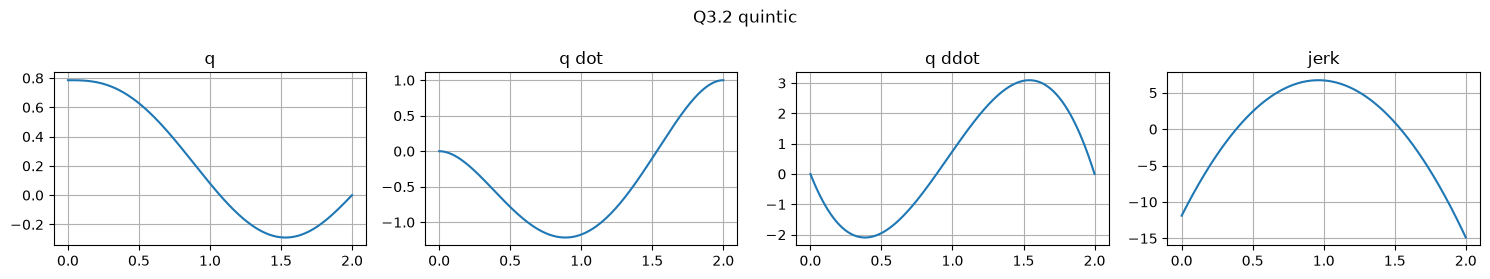

In [27]:
# INPUT (Q3.2)
c = quintic(q0=np.pi/4, qf=0, t0=0, tf=2, v0=0, vf=1, a0=0, af=0)
# expected: 0.7854, 0, 0, -1.982, 1.611, -0.3348
print("check q(2) =", round(poly_eval(c, 2), 4), " qdot(2) =", round(poly_eval(c, 2, 1), 4))
plot_poly(c, 0, 2, "Q3.2 quintic")

In [28]:
# cubic, non-zero start time works too
c3 = cubic(q0=10, qf=40, t0=1, tf=3, v0=0, vf=0)

c0 =  40.0000
c1 = -67.5000
c2 =  45.0000
c3 = -7.5000


### 5b. Any polynomial from any set of conditions
`(t, k, value)` means $q^{(k)}(t)=$ value. E.g. a 4th-order polynomial through start, via-point and end.

In [29]:
c4 = poly_from_conditions([(0, 0, 0), (0, 1, 0), (1, 0, 0.5), (2, 0, 1), (2, 1, 0)])

c0 =  0.0000
c1 =  0.0000
c2 =  0.7500
c3 = -0.2500
c4 =  0.0000


### 5c. LSPB (trapezoidal velocity)

blend time tb = 0.6667, acceleration = 1.1250, cruise speed = 0.7500


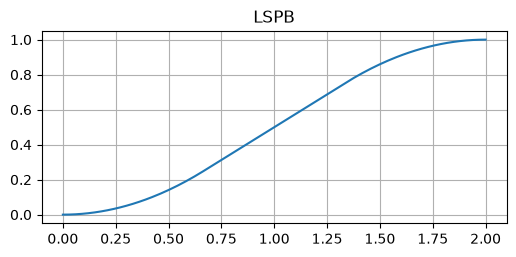

In [30]:
qfun = lspb(q0=0, qf=1, tf=2, V=0.75)
tt = np.linspace(0, 2, 200); plt.figure(figsize=(6, 2.5)); plt.plot(tt, qfun(tt)); plt.grid(); plt.title("LSPB"); plt.show()

### 5d. Constant-jerk path (exam 2016 P3), solved symbolically
$q(0)=0,\ q(10)=100$, rest at both ends, $|\dddot q|\le10$. By symmetry: jerk $+10$ for $t_1$, $-10$ for $t_1$, $0$ until $t=5$, where $q=50$.

In [31]:
t1 = sp.symbols('t1', positive=True)
segs = [(t1, 10), (t1, -10), (5 - 2*t1, 0)]
res = jerk_profile(segs)
q_end = res[-1][0]
roots = sp.Poly(sp.expand(q_end - 50), t1).nroots()
t1_val = [sp.re(r) for r in roots if abs(sp.im(r)) < 1e-9 and 0 < sp.re(r) < 2.5][0]
vmax = res[1][1].subs(t1, t1_val)
print(f"t1 = {float(t1_val):.6f} s,  qdot_max = {float(vmax):.6f}")   # expected 1.137805, 12.946

t1 = 1.137805 s,  qdot_max = 12.946007


---
# 6. Robot vision (Q4.1–Q4.4)
Exam convention: $u=\lambda x/z$, $v=\lambda y/z$, $r=o_r-\alpha_x u$, $c=o_c-\alpha_y v$. **Same length unit as $\lambda$ (mm).**

In [32]:
# INPUT: camera
cam = Camera(lam=8, alpha_x=79.2, alpha_y=120.5, o_r=250, o_c=160)      # sign=-1 (exam convention)
T_b_c = np.array([[1,  0,  0,   0],
                  [0, -1,  0, 300],
                  [0,  0, -1, 500],
                  [0,  0,  0,   1]], float)                              # in mm
depth = 500

# Q4.1: keyboard corners in the camera frame (mm)
corners = np.array([[-30, -30, depth], [-30, 0, depth], [20, 0, depth], [20, -30, depth]])
uv, rc = project(corners, cam, labels=["P1", "P2", "P3", "P4"], round_pix=False)
print("Pc (u row / v row) =\n", np.round(uv.T, 2))

P1: (u,v) = (-0.4800, -0.4800)   (r,c) = (288.02, 217.84)
P2: (u,v) = (-0.4800,  0.0000)   (r,c) = (288.02, 160.00)
P3: (u,v) = ( 0.3200,  0.0000)   (r,c) = (224.66, 160.00)
P4: (u,v) = ( 0.3200, -0.4800)   (r,c) = (224.66, 217.84)
Pc (u row / v row) =
 [[-0.48 -0.48  0.32  0.32]
 [-0.48  0.    0.   -0.48]]


In [33]:
# Q4.2: key centres C, I, A, O in the camera frame (mm)
keys = {"C": (-25, -25), "I": (-15, -15), "A": (5, -25), "O": (15, -5)}
P = np.array([[x, y, depth] for x, y in keys.values()])
project(P, cam, labels=list(keys))
# Q4.3: in the base frame
print("\nbase frame [mm]:\n", to_frame(T_b_c, P))

C: (u,v) = (-0.4000, -0.4000)   (r,c) = (281.68, 208.20)  -> [282; 208]
I: (u,v) = (-0.2400, -0.2400)   (r,c) = (269.01, 188.92)  -> [269; 189]
A: (u,v) = ( 0.0800, -0.4000)   (r,c) = (243.66, 208.20)  -> [244; 208]
O: (u,v) = ( 0.2400, -0.0800)   (r,c) = (230.99, 169.64)  -> [231; 170]

base frame [mm]:
 [[-25. 325.   0.]
 [-15. 315.   0.]
 [  5. 325.   0.]
 [ 15. 305.   0.]]


In [34]:
# Q4.4: camera moved -> express base points in the NEW camera frame, then project
T_b_c2 = np.array([[1, 0, 0, -30], [0, -1, 0, 330], [0, 0, -1, 500], [0, 0, 0, 1]], float)
keys_cam1 = np.array([[-15, -5, depth], [5, -15, depth]])          # keys X and Q in the OLD camera frame
P_base = to_frame(T_b_c, keys_cam1)
P_cam2 = to_frame(Hinv(T_b_c2), P_base)
print("in new camera frame:\n", P_cam2)
project(P_cam2, cam, labels=["X", "Q"]);          # expected X=[231;112], Q=[206;131]

in new camera frame:
 [[ 15.  25. 500.]
 [ 35.  15. 500.]]
X: (u,v) = ( 0.2400,  0.4000)   (r,c) = (230.99, 111.80)  -> [231; 112]
Q: (u,v) = ( 0.5600,  0.2400)   (r,c) = (205.65, 131.08)  -> [206; 131]


In [35]:
# VisionExam: depth from two points 0.3 m apart (pixels 313 and 155 in r)
d_sensor = (313 - 155) / 79.2                 # mm on the sensor
depth_from_size(lam=8, size_world=300, size_sensor=d_sensor);   # mm -> 1200 mm = 1.2 m

# pixel -> 3D with known depth (exam 2016 P4.3, focal length given in pixels)
cam16 = Camera.from_pixels(fx=400, fy=400, o_r=320, o_c=240)
backproject(470, 290, 0.8, cam16);            # expected (-0.3, -0.1, 0.8)

# stereo (exam 2020 P4.3)
stereo_depth(lam=1, B=0.1, u1=0.05, u2=-0.05);

z = 1203.0380
p_cam = [-0.3 -0.1  0.8]
z = 1.0000


---
# 7. Motor control (Q5.1, Q5.2)
Identify every given symbol by its **SI unit** first (V·s/rad = back-emf $K_b$, N·m/A = torque constant $K_t$, kg·m² = inertia, N·m·s/rad = damping).
### 7a. Number of poles of the motor (Q5.1)

In [36]:
# INPUT (Q5.1)
Lm, Rm, Km, Ki = 0.001, 0.9, 0.12, 0.12           # H, Ohm, V s/rad, N m/A
Jm, Dm, Jl, n  = 0.08, 0.027, 0.18, 20
Jeq, Beq = reflected(Jm, Jl, n, Bm=Dm)

G_angle = dc_motor(Lm, Rm, Km, Ki, Jeq, Beq, output="angle")
tf_info(G_angle, "Theta/V");                       # -> 3 poles
print("\nwithout inductance (L = 0):"); tf_info(dc_motor(0, Rm, Km, Ki, Jeq, Beq), "Theta/V (L=0)");

J_eq = 0.08045000000000001, B_eq = 0.027
Theta/V(s) =


order (number of poles) = 3
poles = [-899.801 +0.j   -0.5346+0.j    0.    +0.j]
zeros = []
stable (all Re<0): False | marginal pole at 0: True
DC gain G(0) = oo

without inductance (L = 0):
Theta/V (L=0)(s) =


order (number of poles) = 2
poles = [-0.5345+0.j  0.    +0.j]
zeros = []
stable (all Re<0): False | marginal pole at 0: True
DC gain G(0) = oo


### 7b. Steady-state error with a P / PD / PI controller and a load torque (Q5.2)

In [37]:
# INPUT (Q5.2): controller C(s), step reference and step load torque
kp = 3.78
Theta, ess = motor_position_loop(C=kp, L=Lm, R=Rm, Kb=Km, Kt=Ki, J=Jeq, B=Beq, n=n, ref=1.5, tau_l=0.05)
print("alternative reading (kp is a torque gain at the load): tau_l / kp =", 0.05 / kp)
# both ≈ 0.01 rad -> option "approximately 0.01 rad"

closed-loop poles: [-899.808 -0.j       -0.2638+2.4893j   -0.2638-2.4893j] | stable: True
steady-state error e_ss = 5/1008 ≈ 0.00496032
alternative reading (kp is a torque gain at the load): tau_l / kp = 0.013227513227513229


In [38]:
# try other controllers: PI removes the error, PD does not
kd, ki_ = 0.5, 1.0
motor_position_loop(C=kp + kd*s, L=Lm, R=Rm, Kb=Km, Kt=Ki, J=Jeq, B=Beq, n=n, ref=1.5, tau_l=0.05);
motor_position_loop(C=kp + ki_/s, L=Lm, R=Rm, Kb=Km, Kt=Ki, J=Jeq, B=Beq, n=n, ref=1.5, tau_l=0.05);

closed-loop poles: [-898.9779+0.j       -0.6789+2.4106j   -0.6789-2.4106j] | stable: True
steady-state error e_ss = 5/1008 ≈ 0.00496032


closed-loop poles: [-899.808 +0.j       -0.13  -2.4855j   -0.13  +2.4855j   -0.2676+0.j    ] | stable: True
steady-state error e_ss = 0 ≈ 0


### 7c. Any block diagram: write the loop equations and let sympy solve (exam 2016 P5)
Block diagram of 2016 P5: $(q_r-q)(K_p+K_ds)+(3s+0.45)q_r-D=q(3s+0.5)$.

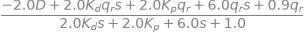

e_ss =


|e_ss| <= 0.01  ->  Kp >= [29.5000000000000]


In [39]:
Kp, Kd, D, qr, qq = sp.symbols('K_p K_d D q_r q')
eq = sp.Eq((qr - qq)*(Kp + Kd*s) + (3*s + 0.45)*qr - D, qq*(3*s + 0.5))
q_s = sp.solve(eq, qq)[0]; display(sp.simplify(q_s))
E = (qr - q_s).subs({qr: 2/s, D: 0.2/s})
ess16 = sp.simplify(sp.limit(s*E, s, 0)); print("e_ss ="); display(ess16)
print("|e_ss| <= 0.01  ->  Kp >=", sp.solve(sp.Eq(ess16, 0.01), Kp))    # expected 29.5

### 7d. Step response, 2nd-order specs, PD design

closed loop(s) =


order (number of poles) = 3
poles = [-899.808 -0.j       -0.2638+2.4893j   -0.2638-2.4893j]
zeros = []
stable (all Re<0): True | marginal pole at 0: False
DC gain G(0) = 1


{'final (at t_end)': 1.4984, 'overshoot %': 71.8565, 'settling time 2%': 14.1917, 'rise time 10-90%': 0.4417}


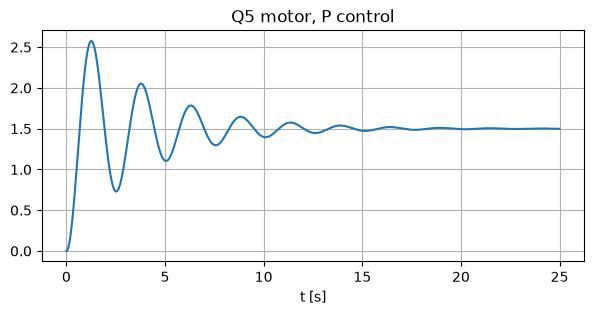

In [40]:
G_cl = feedback(kp * G_angle)          # unity feedback, P controller on Q5.1 motor
tf_info(G_cl, "closed loop");
step_response(G_cl, t_end=25, amplitude=1.5, title="Q5 motor, P control");

In [41]:
second_order_specs(zeta=0.5, wn=10)
zeta_from_OS(10)
pd_design(J=0.5, B=0.1, wn=10, zeta=1);

poles: [-5.+8.6603j -5.-8.6603j]
%OS: 16.3034
t_peak: 0.3628
t_settle(2%)≈: 0.8
zeta = 0.5912
Kp = 50.0000, Kd = 9.9000


In [42]:
# Final / initial value theorem on any F(s)
final_value(5 / (s * (s**2 + 3*s + 2)));
initial_value(5 / (s + 2));

final value = 5/2 ≈ 2.5
initial value = 5


---
# 8. Dynamics (Euler–Lagrange), planar 2R with masses at the link centres

In [43]:
th1, th2, dth1, dth2 = sp.symbols('theta1 theta2 thetadot1 thetadot2')
m1, m2, L1, lc1, lc2, I1, I2, g0 = sp.symbols('m1 m2 l1 l_c1 l_c2 I1 I2 g', positive=True)
q_, qd_ = [th1, th2], [dth1, dth2]
pc1 = [lc1*sp.cos(th1), lc1*sp.sin(th1), 0]
pc2 = [L1*sp.cos(th1) + lc2*sp.cos(th1+th2), L1*sp.sin(th1) + lc2*sp.sin(th1+th2), 0]
Kin = kinetic_point_mass(m1, pc1, q_, qd_) + kinetic_point_mass(m2, pc2, q_, qd_) \
    + sp.Rational(1, 2)*I1*dth1**2 + sp.Rational(1, 2)*I2*(dth1 + dth2)**2
Pot = m1*g0*pc1[1] + m2*g0*pc2[1]
Dm_, Cm_, gm_ = euler_lagrange(q_, qd_, Kin, Pot)

D(q) =


⎡              2         ⎛  2                           2⎞                     ↪
⎢I₁ + I₂ + l_c1 ⋅m₁ + m₂⋅⎝l₁  + 2⋅l₁⋅l_c2⋅cos(θ₂) + l_c2 ⎠  I₂ + l_c2⋅m₂⋅(l₁⋅c ↪
⎢                                                                              ↪
⎢                                                                              ↪
⎣            I₂ + l_c2⋅m₂⋅(l₁⋅cos(θ₂) + l_c2)                        I₂ + l_c2 ↪

↪               ⎤
↪ os(θ₂) + l_c2)⎥
↪               ⎥
↪ 2             ⎥
↪  ⋅m₂          ⎦

C(q,qd) =


⎡-l₁⋅l_c2⋅m₂⋅θ̇₂⋅sin(θ₂)  l₁⋅l_c2⋅m₂⋅(-θ̇₁ - θ̇₂)⋅sin(θ₂)⎤
⎢                                                     ⎥
⎣l₁⋅l_c2⋅m₂⋅θ̇₁⋅sin(θ₂)                 0              ⎦

g(q) =


⎡g⋅(l_c1⋅m₁⋅cos(θ₁) + m₂⋅(l₁⋅cos(θ₁) + l_c2⋅cos(θ₁ + θ₂)))⎤
⎢                                                         ⎥
⎣                 g⋅l_c2⋅m₂⋅cos(θ₁ + θ₂)                  ⎦

---
# 9. Self-test: re-solve the whole Winter 2025-26 MCQ
Runs every computational question and checks the answer. If this cell prints **ALL CHECKS PASSED**, the toolkit works on your machine.

In [44]:
ok = []
T = compose(steps, verbose=False);                     ok.append(np.allclose(T[:3, 3], [13.93, 19.15, 43.30], atol=0.01))
th = ik_2r(0, 592.7, 391, 302, verbose=False)[0];      ok.append(np.allclose(th, [63, 63], atol=0.5))
ok.append(np.allclose(Jv @ [1.371, -3.354], [0, 0.597], atol=1e-3))
c = quintic(np.pi/4, 0, 0, 2, 0, 1, 0, 0, verbose=False); ok.append(np.allclose(c, [0.7854, 0, 0, -1.982, 1.611, -0.3348], atol=1e-3))
_, rc = project(P, cam, verbose=False);                ok.append(np.allclose(np.round(rc), [[282, 208], [269, 189], [244, 208], [231, 170]]))
_, rc2 = project(P_cam2, cam, verbose=False);          ok.append(np.allclose(np.round(rc2), [[231, 112], [206, 131]]))
num, den = sp.fraction(sp.together(G_angle));          ok.append(sp.degree(den, s) == 3)
ok.append(abs(float(ess) - 0.00496) < 1e-4)
print(ok)
print("ALL CHECKS PASSED ✔" if all(ok) else "SOMETHING FAILED ✘")

[True, True, True, True, True, True, True, True]
ALL CHECKS PASSED ✔
